# Classical baselines: The 64-Copy Problem (XXZ)

## 1. Setup

In [1]:
import sys, pathlib, time, json
import numpy as np
import matplotlib.pyplot as plt

KIT = pathlib.Path("../datasets/SEND_TO_PARTICIPANTS-1").resolve()
assert KIT.exists(), f"kit not found at {KIT}"
sys.path.insert(0, str(KIT))
from oracle import CopyOracle, CopyBudgetExceeded

N_QUBITS, BUDGET = 16, 64
PHASES = ["FM", "XY", "NEEL"]
rng = np.random.default_rng(0)
print("kit:", KIT)

kit: datasets\SEND_TO_PARTICIPANTS-1


## 2. Load the public training set

In [2]:
data   = np.load(KIT / "xxz_public_train.npz", allow_pickle=True)
states = data["states"].astype(np.float64)
ids    = [str(x) for x in data["ids"]]
deltas = data["deltas"]
labels = np.array([str(x) for x in data["labels"]])

print(str(data["model"]))
print(str(data["convention"]))
print(f"{len(ids)} states, {int(data['num_qubits'])} qubits")
for p in PHASES:
    d = deltas[labels == p]
    print(f"  {p:5s} n={np.sum(labels==p):2d}  delta in [{d.min():+.2f}, {d.max():+.2f}]")

XXZ chain, N=16, periodic BC, symmetry-breaking field h=1e-4
qml.StatePrep(state, wires=range(16)) puts chain site i on wire i; |0> on a wire = spin up (Sz=+1/2). Labels: FM (delta<-1), XY (-1<delta<1), NEEL (delta>1).
48 states, 16 qubits
  FM    n=14  delta in [-2.50, -1.30]
  XY    n=20  delta in [-0.70, +0.70]
  NEEL  n=14  delta in [+1.30, +2.50]


Training deltas leave a gap around the phase boundaries at Δ = ±1.

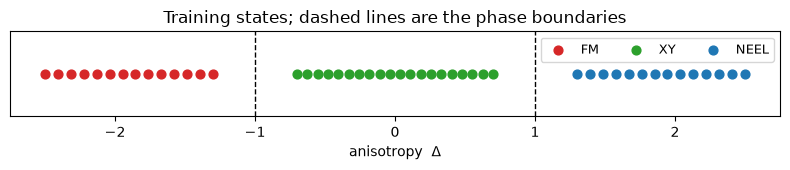

In [3]:
fig, ax = plt.subplots(figsize=(8, 1.8))
for p, c in zip(PHASES, ["tab:red", "tab:green", "tab:blue"]):
    ax.scatter(deltas[labels == p], np.zeros((labels == p).sum()), s=40, label=p, color=c)
for b in (-1, 1):
    ax.axvline(b, color="k", ls="--", lw=1)
ax.set_yticks([]); ax.set_xlabel("anisotropy  $\Delta$"); ax.legend(ncol=3, fontsize=9)
ax.set_title("Training states; dashed lines are the phase boundaries")
plt.tight_layout(); plt.show()

## 3. Basis-state lookup tables

In [4]:
idx   = np.arange(2 ** N_QUBITS)
bits  = ((idx[:, None] >> np.arange(N_QUBITS - 1, -1, -1)) & 1).astype(np.int8)
spin  = (1 - 2 * bits).astype(np.float32)

TAB = {
    "m_abs": np.abs(spin.mean(1)),
    "stag":  np.abs((spin * (-1.0) ** np.arange(N_QUBITS)).mean(1)),
    "c1":    (spin * np.roll(spin, -1, axis=1)).mean(1),
    "pair":  (spin[:, 0::2] * spin[:, 1::2]).mean(1),
}
SZ = spin.sum(1)
print({k: v.shape for k, v in TAB.items()})

{'m_abs': (65536,), 'stag': (65536,), 'c1': (65536,), 'pair': (65536,)}


## 4. Exact phase signatures

In [5]:
def exact_probs(k):
    p = states[k] ** 2
    return p / p.sum()

rows = []
for k in range(len(ids)):
    p = exact_probs(k)
    rows.append([deltas[k]] + [float(p @ TAB[s]) for s in ("m_abs", "stag", "c1", "pair")]
                + [float(p[SZ == 0].sum())])
sig = np.array(rows)

print(f"{'phase':6s} {'|m|':>7s} {'stag':>7s} {'c1':>7s} {'pair':>7s} {'P(Sz=0)':>8s}")
for p in PHASES:
    v = sig[labels == p].mean(0)
    print(f"{p:6s} {v[1]:7.3f} {v[2]:7.3f} {v[3]:+7.3f} {v[4]:+7.3f} {v[5]:8.3f}")

phase      |m|    stag      c1    pair  P(Sz=0)
FM       1.000   0.000  +1.000  +1.000    0.000
XY       0.000   0.280  -0.403  -0.403    1.000
NEEL     0.000   0.680  -0.762  -0.762    1.000


FM is fully polarized; XY and NEEL differ in staggered magnetization.

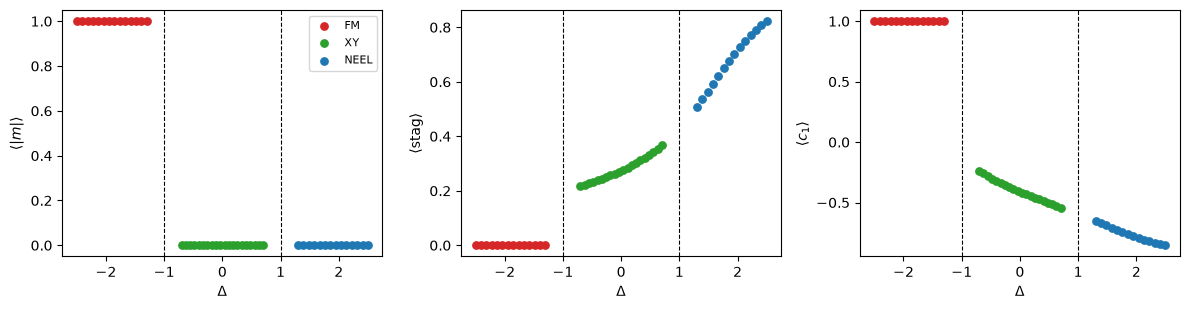

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, j, name in zip(axes, [1, 2, 3], [r"$\langle|m|\rangle$", r"$\langle$stag$\rangle$", r"$\langle c_1\rangle$"]):
    for p, c in zip(PHASES, ["tab:red", "tab:green", "tab:blue"]):
        m = labels == p
        ax.scatter(sig[m, 0], sig[m, j], s=28, color=c, label=p)
    for b in (-1, 1):
        ax.axvline(b, color="k", ls="--", lw=0.8)
    ax.set_xlabel(r"$\Delta$"); ax.set_ylabel(name)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. The oracle

In [7]:
practice = CopyOracle(KIT / "xxz_public_train.npz", copy_budget=BUDGET,
                      noise_p=0.02, seed=0)

s = practice.measure("T00")
print("one copy of T00:", s, "| remaining:", practice.remaining("T00"))

for _ in range(63):
    practice.measure("T00")
try:
    practice.measure("T00")
except CopyBudgetExceeded as e:
    print("copy 65 refused:", e)

one copy of T00: [0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0] | remaining: 63


copy 65 refused: copy budget (64) exhausted for T00


## 6. Readout from one measurement

In [8]:
def readout(shots):
    """(k, 16) of 0/1 -> dict of per-shot statistics. Free: no extra copies."""
    s = 1.0 - 2.0 * np.atleast_2d(np.asarray(shots, dtype=float))
    return {
        "m_abs": np.abs(s.mean(1)),
        "stag":  np.abs((s * (-1.0) ** np.arange(s.shape[1])).mean(1)),
        "c1":    (s * np.roll(s, -1, axis=1)).mean(1),
        "pair":  (s[:, 0::2] * s[:, 1::2]).mean(1),
        "sz":    s.sum(1),
    }

demo = CopyOracle(KIT / "xxz_public_train.npz", copy_budget=BUDGET, noise_p=0.0, seed=1)
for sid in ("T00", "T24", "T47"):
    r = readout(demo.measure(sid))
    lab = labels[ids.index(sid)]
    print(f"{sid} ({lab:4s}): |m|={r['m_abs'][0]:.3f}  stag={r['stag'][0]:.3f}  "
          f"c1={r['c1'][0]:+.3f}  Sz={r['sz'][0]:+.0f}")

T00 (FM  ): |m|=1.000  stag=0.000  c1=+1.000  Sz=+16
T24 (XY  ): |m|=0.000  stag=0.000  c1=-0.250  Sz=+0
T47 (NEEL): |m|=0.000  stag=1.000  c1=-1.000  Sz=+0


## 7. Noise model

Depolarizing applies X, Y or Z with probability p/3 each; X and Y flip a computational-basis bit and Z does not, so each bit flips with probability 2p/3.

In [9]:
def bitflip_channel(prob_vec, q):
    """Apply an independent bit-flip channel of rate q to a distribution over 2^N strings."""
    if q <= 0:
        return prob_vec
    t = prob_vec.reshape((2,) * N_QUBITS).copy()
    M = np.array([[1 - q, q], [q, 1 - q]])
    for ax in range(N_QUBITS):
        t = np.moveaxis(np.tensordot(M, np.moveaxis(t, ax, 0), axes=(1, 0)), 0, ax)
    return t.reshape(-1)

k_neel = int(np.where(labels == "NEEL")[0][5])
print(f"{'noise p':>8s} {'predicted':>10s} {'oracle':>8s}")
for p_noise in (0.0, 0.02, 0.05, 0.10):
    pred = bitflip_channel(exact_probs(k_neel), 2 * p_noise / 3) @ TAB["m_abs"]
    o = CopyOracle(KIT / "xxz_public_train.npz", copy_budget=BUDGET, noise_p=p_noise, seed=3)
    emp = readout(np.stack([o.measure(ids[k_neel]) for _ in range(BUDGET)]))["m_abs"].mean()
    print(f"{p_noise:8.2f} {pred:10.3f} {emp:8.3f}")

 noise p  predicted   oracle


    0.00      0.000    0.000


    0.02      0.024    0.021


    0.05      0.052    0.049


    0.10      0.086    0.076


## 8. Likelihood over discrete readout symbols

In [10]:
FEATURES = ("m_abs", "stag")

def symbol_grid(features=FEATURES):
    """Every distinct readout value a 16-bit string can produce."""
    cols = np.stack([TAB[f] for f in features], axis=1).round(9)
    uniq, inv = np.unique(cols, axis=0, return_inverse=True)
    return uniq, inv

SYMBOLS, SYM_OF_BASIS = symbol_grid()
print(f"{len(SYMBOLS)} distinct symbols from {2**N_QUBITS} basis strings")

def class_tables(noise_p, smoothing=1e-3, features=FEATURES):
    """Exact P(symbol | phase) under the given noise, from the training states."""
    q = 2 * noise_p / 3
    tab = np.zeros((len(PHASES), len(SYMBOLS)))
    for c, phase in enumerate(PHASES):
        avg = np.mean([exact_probs(k) for k in np.where(labels == phase)[0]], axis=0)
        np.add.at(tab[c], SYM_OF_BASIS, bitflip_channel(avg, q))
    tab += smoothing
    return tab / tab.sum(1, keepdims=True)

def assign(stats, features=FEATURES):
    """Map observed readout rows to the nearest symbol."""
    X = np.stack([stats[f] for f in features], axis=1)
    return np.argmin(((X[:, None, :] - SYMBOLS[None, :, :]) ** 2).sum(-1), axis=1)

25 distinct symbols from 65536 basis strings


Log-likelihoods add over copies; the prior is applied once.

In [11]:
LOG_PRIOR = np.log(np.array([np.mean(labels == p) for p in PHASES]))

def accumulate(log_lik, log_prior=LOG_PRIOR):
    """(k, C) per-copy log-likelihoods -> (k, C) running log-posteriors."""
    return log_prior[None, :] + np.cumsum(log_lik, axis=0)

## 9. Baseline 1: order-parameter likelihood

In [12]:
def draw(oracle, sid, k, ops_fn=None):
    return np.stack([oracle.measure(sid, ops_fn=ops_fn) for _ in range(k)])

def baseline_orderparam(shots, table):
    ll = np.log(table[:, assign(readout(shots))]).T
    return accumulate(ll)

NOISE_P = 0.02
TABLE = class_tables(NOISE_P)

o = CopyOracle(KIT / "xxz_public_train.npz", copy_budget=BUDGET, noise_p=NOISE_P, seed=11)
t0 = time.time()
SHOTS = {sid: draw(o, sid, BUDGET) for sid in ids}
print(f"drew {BUDGET} copies x {len(ids)} states in {time.time()-t0:.0f}s")
print("max copies used on any state:", max(o.usage_report().values()))

drew 64 copies x 48 states in 15s
max copies used on any state: 64


In [13]:
KS = (1, 2, 4, 8, 16, 32, 64)

def accuracy_curve(predict_fn):
    out = {}
    for k in KS:
        pred = [PHASES[predict_fn(SHOTS[sid][:k])] for sid in ids]
        out[k] = float(np.mean(np.array(pred) == labels))
    return out

acc_op = accuracy_curve(lambda sh: int(np.argmax(baseline_orderparam(sh, TABLE)[-1])))
print("order-parameter likelihood:", {k: round(v, 3) for k, v in acc_op.items()})

order-parameter likelihood: {1: 0.917, 2: 0.896, 4: 0.958, 8: 0.979, 16: 1.0, 32: 1.0, 64: 1.0}


## 10. Baseline 2: classical shadows + logistic regression

In [14]:
import pennylane as qml
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

def shadow_ops(basis):
    """Rotate each wire into a random Pauli basis before measurement."""
    def ops(wires):
        for w, b in zip(wires, basis):
            if b == 0:
                qml.Hadamard(w)
            elif b == 1:
                qml.adjoint(qml.S(w)); qml.Hadamard(w)
    return ops

def shadow_features(snap_bits, snap_basis):
    """Translation-averaged weight-1 and weight-2 Pauli estimates."""
    s = 1.0 - 2.0 * snap_bits
    f = []
    for b in range(3):
        m = (snap_basis == b).astype(float)
        f.append(float((3.0 * s * m).sum(0).mean() / max(m.sum(0).mean(), 1e-9)))
    for d in (1, 2):
        for b in range(3):
            m = ((snap_basis == b) & (np.roll(snap_basis, -d, 1) == b)).astype(float)
            pr = s * np.roll(s, -d, axis=1)
            f.append(float((9.0 * pr * m).sum(0).mean() / max(m.sum(0).mean(), 1e-9)))
    f.append(float(((3.0 * s * (snap_basis == 2)).mean(1) ** 2).mean()))
    return np.array(f)

def draw_shadows(oracle, sid, k, rng):
    bits, base = [], []
    for _ in range(k):
        b = rng.integers(0, 3, size=N_QUBITS)
        bits.append(oracle.measure(sid, ops_fn=shadow_ops(b))); base.append(b)
    return np.stack(bits).astype(float), np.stack(base)

rs = np.random.default_rng(5)
osh = CopyOracle(KIT / "xxz_public_train.npz", copy_budget=BUDGET, noise_p=NOISE_P, seed=12)
t0 = time.time()
SHADOWS = {sid: draw_shadows(osh, sid, BUDGET, rs) for sid in ids}
print(f"drew shadow snapshots in {time.time()-t0:.0f}s | "
      f"max copies {max(osh.usage_report().values())}")

drew shadow snapshots in 54s | max copies 64


Trained per k, since the estimator variance depends on the number of copies.

In [15]:
def shadow_accuracy():
    out = {}
    for k in KS:
        F = np.stack([shadow_features(SHADOWS[s][0][:k], SHADOWS[s][1][:k]) for s in ids])
        sc = StandardScaler().fit(F)
        preds = []
        for i in range(len(ids)):
            tr = np.setdiff1d(np.arange(len(ids)), i)
            clf = LogisticRegression(max_iter=3000).fit(sc.transform(F[tr]), labels[tr])
            preds.append(clf.predict(sc.transform(F[i:i+1]))[0])
        out[k] = float(np.mean(np.array(preds) == labels))
    return out

acc_shadow = shadow_accuracy()
print("shadows + logistic regression:", {k: round(v, 3) for k, v in acc_shadow.items()})

shadows + logistic regression: {1: 0.688, 2: 0.688, 4: 0.792, 8: 0.812, 16: 0.917, 32: 0.938, 64: 0.979}


## 11. Baseline 3: neural network on bitstrings

A classifier outputs `log P(class | shot)`.

In [16]:
import torch, torch.nn as nn

class ShotCNN(nn.Module):
    """1D convolution with global pooling: size-agnostic, translation-equivariant."""
    def __init__(self, ch=24, n_classes=3):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(1, ch, 3, padding=1, padding_mode="circular"),
                                 nn.ReLU(),
                                 nn.Conv1d(ch, ch, 3, padding=1, padding_mode="circular"),
                                 nn.ReLU())
        self.head = nn.Linear(ch, n_classes)
    def forward(self, x):
        return self.head(self.net(x.unsqueeze(1)).mean(-1))

def train_cnn(shots_by_state, y, seed=0, steps=400):
    torch.manual_seed(seed)
    X = torch.tensor(np.concatenate([1.0 - 2.0 * shots_by_state[s] for s in ids]),
                     dtype=torch.float32)
    Y = torch.tensor(np.repeat(y, BUDGET), dtype=torch.long)
    net = ShotCNN(); opt = torch.optim.Adam(net.parameters(), lr=0.01)
    for _ in range(steps):
        opt.zero_grad(); loss = nn.functional.cross_entropy(net(X), Y)
        loss.backward(); opt.step()
    return net, float(loss)

y_int = np.array([PHASES.index(l) for l in labels])
cnn, final_loss = train_cnn(SHOTS, y_int)
print(f"trained, final loss {final_loss:.4f}")

@torch.no_grad()
def cnn_log_lik(net, shots, log_prior=LOG_PRIOR):
    x = torch.tensor(1.0 - 2.0 * np.atleast_2d(shots), dtype=torch.float32)
    post = torch.log_softmax(net(x), dim=-1).numpy()
    return post - log_prior[None, :]

acc_cnn      = accuracy_curve(lambda sh: int(np.argmax(accumulate(cnn_log_lik(cnn, sh))[-1])))
acc_cnn_bug  = accuracy_curve(lambda sh: int(np.argmax(np.cumsum(
    torch.log_softmax(cnn(torch.tensor(1.0-2.0*np.atleast_2d(sh), dtype=torch.float32)),
                      dim=-1).detach().numpy(), axis=0)[-1])))
print("CNN, prior removed :", {k: round(v, 3) for k, v in acc_cnn.items()})
print("CNN, prior left in :", {k: round(v, 3) for k, v in acc_cnn_bug.items()})

C:\Users\Youssef Kamel\AppData\Local\Temp\ipykernel_33104\3992035668.py:24: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  return net, float(loss)


trained, final loss 0.3123


CNN, prior removed : {1: 0.917, 2: 0.917, 4: 0.979, 8: 0.979, 16: 1.0, 32: 1.0, 64: 1.0}
CNN, prior left in : {1: 0.917, 2: 0.917, 4: 0.938, 8: 0.938, 16: 0.979, 32: 0.938, 64: 0.958}


The uncorrected curve degrades with more copies; the corrected one does not.

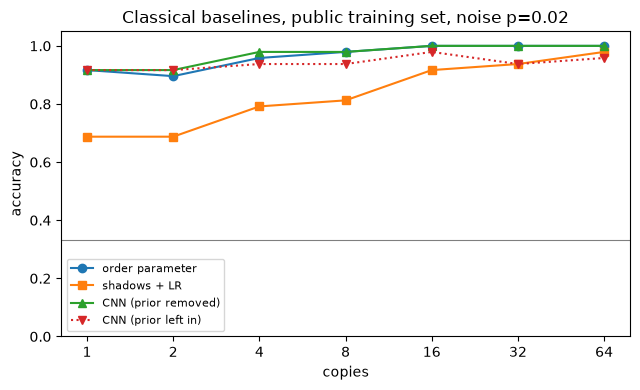

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, a, st in (("order parameter", acc_op, "o-"),
                    ("shadows + LR", acc_shadow, "s-"),
                    ("CNN (prior removed)", acc_cnn, "^-"),
                    ("CNN (prior left in)", acc_cnn_bug, "v:")):
    ax.plot(list(a), list(a.values()), st, label=name)
ax.axhline(1/3, color="k", lw=0.8, alpha=0.5)
ax.set_xscale("log", base=2); ax.set_xticks(KS); ax.set_xticklabels(KS)
ax.set_xlabel("copies"); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.05)
ax.set_title(f"Classical baselines, public training set, noise p={NOISE_P}")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 12. Impostor detection

Under Jordan-Wigner the impostors put two spin species of one site on wires (2i, 2i+1); for XXZ every wire is an equivalent chain site, so `pair - c1` is zero.

In [18]:
try:
    fh = qml.data.load("qspin", sysname="FermiHubbard", periodicity="open",
                       lattice="chain", layout="1x8")[0]
    FH = np.stack([np.abs(np.asarray(fh.ground_states[k]))**2 for k in range(0, 100, 4)])
    FH /= FH.sum(1, keepdims=True)
    have_fh = True
except Exception as e:
    print("could not fetch Fermi-Hubbard proxies:", e); have_fh = False

if have_fh:
    print(f"{'set':12s} {'c1':>8s} {'pair':>8s} {'pair-c1':>9s}")
    for p in PHASES:
        avg = np.mean([exact_probs(k) for k in np.where(labels == p)[0]], axis=0)
        print(f"XXZ {p:8s} {avg@TAB['c1']:+8.3f} {avg@TAB['pair']:+8.3f} "
              f"{avg@TAB['pair']-avg@TAB['c1']:+9.3f}")
    m = FH.mean(0)
    print(f"{'FermiHubbard':12s} {m@TAB['c1']:+8.3f} {m@TAB['pair']:+8.3f} "
          f"{m@TAB['pair']-m@TAB['c1']:+9.3f}")

set                c1     pair   pair-c1
XXZ FM         +1.000   +1.000    +0.000
XXZ XY         -0.403   -0.403    -0.000
XXZ NEEL       -0.762   -0.762    -0.000
FermiHubbard   -0.477   -0.742    -0.265


XXZ  pair-c1: mean -0.007  min -0.082
FH   pair-c1: mean -0.243  max -0.160
threshold -0.075 -> recall 1.000, false rejects 0.021


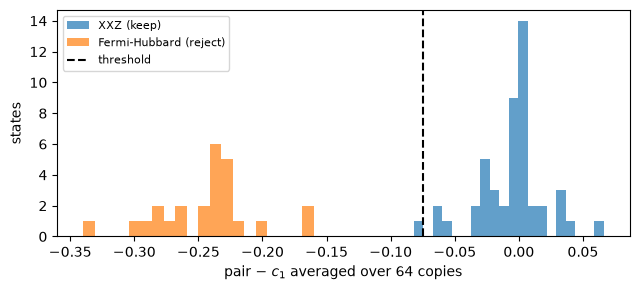

In [19]:
if have_fh:
    def impostor_score(shots):
        r = readout(shots)
        return float(np.mean(r["pair"] - r["c1"]))

    xxz_scores = np.array([impostor_score(SHOTS[s]) for s in ids])
    q = 2 * NOISE_P / 3
    fh_scores = []
    for row in FH:
        pr = bitflip_channel(row, q)
        draws = rng.choice(len(pr), size=BUDGET, p=pr / pr.sum())
        fh_scores.append(float(np.mean(TAB["pair"][draws] - TAB["c1"][draws])))
    fh_scores = np.array(fh_scores)

    thr = np.percentile(xxz_scores, 1.0)
    print(f"XXZ  pair-c1: mean {xxz_scores.mean():+.3f}  min {xxz_scores.min():+.3f}")
    print(f"FH   pair-c1: mean {fh_scores.mean():+.3f}  max {fh_scores.max():+.3f}")
    print(f"threshold {thr:+.3f} -> recall {np.mean(fh_scores < thr):.3f}, "
          f"false rejects {np.mean(xxz_scores < thr):.3f}")

    fig, ax = plt.subplots(figsize=(6.5, 3))
    ax.hist(xxz_scores, bins=20, alpha=0.7, label="XXZ (keep)")
    ax.hist(fh_scores, bins=20, alpha=0.7, label="Fermi-Hubbard (reject)")
    ax.axvline(thr, color="k", ls="--", label="threshold")
    ax.set_xlabel("pair $-$ $c_1$ averaged over 64 copies"); ax.set_ylabel("states")
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 13. Robustness to the noise level

In [20]:
rows = []
for p_noise in (0.0, 0.02, 0.05, 0.10):
    op = CopyOracle(KIT / "xxz_public_train.npz", copy_budget=BUDGET,
                    noise_p=p_noise, seed=21)
    sh = {s: draw(op, s, 16) for s in ids}
    tbl = class_tables(p_noise)
    for k in (4, 8, 16):
        pred = [PHASES[int(np.argmax(baseline_orderparam(sh[s][:k], tbl)[-1]))] for s in ids]
        rows.append((p_noise, k, float(np.mean(np.array(pred) == labels))))

print(f"{'noise':>6s} " + " ".join(f"{'k='+str(k):>8s}" for k in (4, 8, 16)))
for p_noise in (0.0, 0.02, 0.05, 0.10):
    v = [a for (pn, k, a) in rows if pn == p_noise]
    print(f"{p_noise:6.2f} " + " ".join(f"{x:8.3f}" for x in v))

 noise      k=4      k=8     k=16
  0.00    0.917    0.958    0.958
  0.02    0.917    0.958    1.000
  0.05    0.958    0.979    1.000
  0.10    0.917    0.938    0.979


## 14. Copy accounting

In [21]:
use = np.array(list(o.usage_report().values()))
print(f"states {len(use)} | mean {use.mean():.1f} | min {use.min()} | max {use.max()} "
      f"| budget {BUDGET}")
assert use.max() <= BUDGET, "budget violated"
print("within budget on every state")

states 48 | mean 64.0 | min 64 | max 64 | budget 64
within budget on every state


In [22]:
summary = {"order parameter": acc_op, "shadows + LR": acc_shadow,
           "CNN (prior removed)": acc_cnn, "CNN (prior left in)": acc_cnn_bug}
print(f"{'baseline':22s} " + " ".join(f"{('k='+str(k)):>7s}" for k in KS))
for name, a in summary.items():
    print(f"{name:22s} " + " ".join(f"{a[k]:7.3f}" for k in KS))
print("\nchance = 0.333 (3 classes)")
json.dump({k: {str(a): b for a, b in v.items()} for k, v in summary.items()},
          open("classical_baselines.json", "w"), indent=1)

baseline                   k=1     k=2     k=4     k=8    k=16    k=32    k=64
order parameter          0.917   0.896   0.958   0.979   1.000   1.000   1.000
shadows + LR             0.688   0.688   0.792   0.812   0.917   0.938   0.979
CNN (prior removed)      0.917   0.917   0.979   0.979   1.000   1.000   1.000
CNN (prior left in)      0.917   0.917   0.938   0.938   0.979   0.938   0.958

chance = 0.333 (3 classes)


## 15. Near-boundary states

The training deltas skip the region around the boundaries at $\Delta=\pm1$, so the sections above never test the regime where the phases are hardest to tell apart.

In [23]:
gaps = [(-1.30, -0.70), (0.70, 1.30)]
print("training deltas, sorted:")
print(np.round(np.sort(deltas), 2))
for lo, hi in gaps:
    print(f"  states with {lo} < delta < {hi}: {int(((deltas > lo) & (deltas < hi)).sum())}")

training deltas, sorted:
[-2.5  -2.41 -2.32 -2.22 -2.13 -2.04 -1.95 -1.85 -1.76 -1.67 -1.58 -1.48
 -1.39 -1.3  -0.7  -0.63 -0.55 -0.48 -0.41 -0.33 -0.26 -0.18 -0.11 -0.04
  0.04  0.11  0.18  0.26  0.33  0.41  0.48  0.55  0.63  0.7   1.3   1.39
  1.48  1.58  1.67  1.76  1.85  1.95  2.04  2.13  2.22  2.32  2.41  2.5 ]
  states with -1.3 < delta < -0.7: 0
  states with 0.7 < delta < 1.3: 0


Solving the XXZ chain ourselves lets us make states at any Δ.

In [24]:
import scipy.sparse as sp
import scipy.sparse.linalg as sla

def xxz_hamiltonian(delta, h=1e-4, n=N_QUBITS):
    """XXZ chain, periodic, with the same symmetry-breaking field as the kit."""
    dim = 2 ** n
    ix = np.arange(dim)
    sgn = 1 - 2 * ((ix[:, None] >> np.arange(n - 1, -1, -1)) & 1).astype(np.int8)

    diag = np.zeros(dim)
    for i in range(n):
        diag += 0.25 * delta * sgn[:, i] * sgn[:, (i + 1) % n]
    diag -= h * 0.5 * sgn.sum(1)
    H = sp.diags(diag).tocsr()

    rows, cols = [], []
    for i in range(n):
        j = (i + 1) % n
        bi, bj = 1 << (n - 1 - i), 1 << (n - 1 - j)
        opp = ((ix & bi) != 0) != ((ix & bj) != 0)
        rows.append(ix[opp]); cols.append(ix[opp] ^ bi ^ bj)
    r, c = np.concatenate(rows), np.concatenate(cols)
    return (H + sp.csr_matrix((np.full(len(r), 0.5), (r, c)), shape=(dim, dim))).tocsr()

def xxz_ground_state(delta):
    _, v = sla.eigsh(xxz_hamiltonian(delta), k=1, which="SA", tol=1e-9)
    return v[:, 0] / np.linalg.norm(v[:, 0])

check = [0, 20, 47]
print("fidelity against the shipped states:")
for k in check:
    psi = xxz_ground_state(float(deltas[k]))
    ref = states[k] / np.linalg.norm(states[k])
    print(f"  delta={deltas[k]:+6.2f} ({labels[k]:4s})  {abs(psi @ ref) ** 2:.6f}")

fidelity against the shipped states:


  delta= -2.50 (FM  )  1.000000
  delta= -0.26 (XY  )  1.000000


  delta= +2.50 (NEEL)  1.000000


Build states inside the gap, labelled by the same rule the kit uses.

In [25]:
def phase_of(delta):
    return "FM" if delta < -1 else ("NEEL" if delta > 1 else "XY")

NEAR_DELTAS = np.concatenate([
    np.linspace(-1.28, -0.72, 15),
    np.linspace(0.72, 1.28, 15),
])
NEAR_DELTAS = NEAR_DELTAS[np.abs(np.abs(NEAR_DELTAS) - 1) > 0.02]

t0 = time.time()
near_states = np.stack([xxz_ground_state(float(d)) for d in NEAR_DELTAS])
near_labels = np.array([phase_of(float(d)) for d in NEAR_DELTAS])
print(f"{len(NEAR_DELTAS)} near-boundary states in {time.time()-t0:.0f}s")
for p in PHASES:
    print(f"  {p:5s} {int((near_labels == p).sum())}")

28 near-boundary states in 9s
  FM    7
  XY    14
  NEEL  7


Sampling from these mirrors the oracle: same noise channel, same 64-copy cap.

In [26]:
def sample_state(psi, k, noise_p, rng):
    """One measurement per copy, with the oracle's depolarizing noise applied."""
    pr = bitflip_channel(np.abs(psi) ** 2, 2 * noise_p / 3)
    draws = rng.choice(len(pr), size=k, p=pr / pr.sum())
    return bits[draws]

rng2 = np.random.default_rng(7)
NEAR_SHOTS = np.stack([sample_state(psi, BUDGET, NOISE_P, rng2) for psi in near_states])
print("shots:", NEAR_SHOTS.shape, "| copies per state:", NEAR_SHOTS.shape[1], "of", BUDGET)

shots: (28, 64, 16) | copies per state: 64 of 64


The same baseline, unchanged, on states it was never trained near.

In [27]:
def curve_on(shots_arr, truth, predict_fn):
    out = {}
    for k in KS:
        pred = np.array([PHASES[predict_fn(sh[:k])] for sh in shots_arr])
        out[k] = float(np.mean(pred == truth))
    return out

acc_near = curve_on(NEAR_SHOTS, near_labels,
                    lambda sh: int(np.argmax(baseline_orderparam(sh, TABLE)[-1])))
acc_near_cnn = curve_on(NEAR_SHOTS, near_labels,
                        lambda sh: int(np.argmax(accumulate(cnn_log_lik(cnn, sh))[-1])))

print(f"{'baseline':22s} " + " ".join(f"{('k='+str(k)):>7s}" for k in KS))
for name, easy, hard in (("order parameter", acc_op, acc_near),
                         ("CNN (prior removed)", acc_cnn, acc_near_cnn)):
    print(f"{name+' [train]':22s} " + " ".join(f"{easy[k]:7.3f}" for k in KS))
    print(f"{name+' [near bdy]':22s} " + " ".join(f"{hard[k]:7.3f}" for k in KS))

baseline                   k=1     k=2     k=4     k=8    k=16    k=32    k=64
order parameter [train]   0.917   0.896   0.958   0.979   1.000   1.000   1.000
order parameter [near bdy]   0.750   0.857   0.857   0.821   0.857   0.786   0.857
CNN (prior removed) [train]   0.917   0.917   0.979   0.979   1.000   1.000   1.000
CNN (prior removed) [near bdy]   0.750   0.857   0.821   0.786   0.786   0.786   0.786


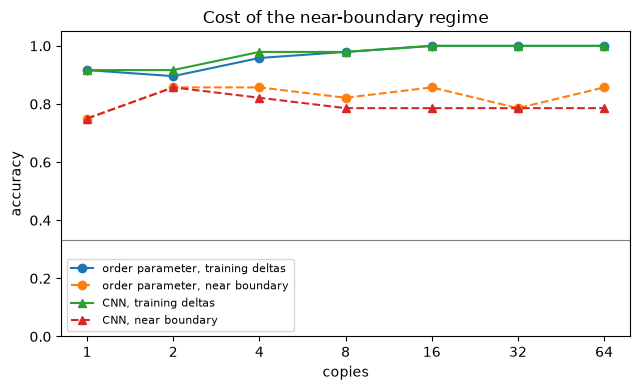

In [28]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(list(acc_op), list(acc_op.values()), "o-", label="order parameter, training deltas")
ax.plot(list(acc_near), list(acc_near.values()), "o--", label="order parameter, near boundary")
ax.plot(list(acc_cnn), list(acc_cnn.values()), "^-", label="CNN, training deltas")
ax.plot(list(acc_near_cnn), list(acc_near_cnn.values()), "^--", label="CNN, near boundary")
ax.axhline(1 / 3, color="k", lw=0.8, alpha=0.5)
ax.set_xscale("log", base=2); ax.set_xticks(KS); ax.set_xticklabels(KS)
ax.set_xlabel("copies"); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.05)
ax.set_title("Cost of the near-boundary regime")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Accuracy against distance from the boundary, at a fixed 16 copies.

In [29]:
k_fix = 16
correct = np.array([PHASES[int(np.argmax(baseline_orderparam(sh[:k_fix], TABLE)[-1]))] == t
                    for sh, t in zip(NEAR_SHOTS, near_labels)])
dist = np.abs(np.abs(NEAR_DELTAS) - 1)

order = np.argsort(dist)
edges = np.array_split(order, 5)
print(f"{'|delta|-1':>12s} {'n':>4s} {'accuracy':>9s}")
for e in edges:
    print(f"{dist[e].mean():12.3f} {len(e):4d} {correct[e].mean():9.3f}")

   |delta|-1    n  accuracy
       0.053    6     0.667
       0.107    6     1.000
       0.173    6     0.833
       0.224    5     0.800
       0.272    5     1.000
